# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170243          # <-- your full roll number
NAME = "Dhruv"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170243   Name: Dhruv   Fingerprint: F225694F   Tickets: 15

Ticket_ID                                                                               Ticket_Text
      T01                         I reinstalled the student portal since yesterday. This is urgent.
      T02                                              The laptop is showing an error. Please help.
      T03       I couldn't connect to the student portal when I use mobile hotspot. This is urgent.
      T04                                                     Nothing works and nobody has replied.
      T05 I am unable to use the projector after resetting my password. I have tried several times!
      T06                                            Re-installing didn't help; log-in still fails!
      T07                                                      Python 3.12 was installed yesterday.
      T08                    VPN was working yesterday before the assignment deadline. Please help.
      T09   E-mail cras

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
data = []
for index, row in df.iterrows():
    r = process_ticket(row["Ticket_Text"])
    data.append([
        row["Ticket_ID"],
        len(r["sentences"]),
        len(r["tokens"]),
        len(r["punct"]),
        len(r["stops"]),
        len(set(r["tokens"])),
        len(r["final"])
    ])
result = pd.DataFrame(data, columns=[
    "Ticket_ID", "Sentences", "Tokens", "Punctuation",
    "Stopwords", "Unique Tokens", "Final Tokens"
])
result.loc[len(result)] = [
    "TOTAL",
    result["Sentences"].sum(),
    result["Tokens"].sum(),
    result["Punctuation"].sum(),
    result["Stopwords"].sum(),
    result["Unique Tokens"].sum(),
    result["Final Tokens"].sum()
]
print(result.to_string(index=False))

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique Tokens  Final Tokens
      T01          2      12            2          4             11             6
      T02          2      10            2          3              9             5
      T03          2      18            2          7             16             9
      T04          1       7            1          2              7             4
      T05          2      18            2          8             17             8
      T06          1       9            2          1              9             6
      T07          1       6            1          1              6             4
      T08          2      12            2          3             11             7
      T09          2      15            2          5             15             8
      T10          2      14            2          5             12             7
      T11          2      15            2          5             15             8
      T12       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
texts = df["Ticket_Text"].tolist() + TEST_LINES
for text in texts:
    print("\nText:", text)
    print("Long words:", re.findall(r"\b[A-Za-z]{6,}\b", text))
    print("Numbers:", re.findall(r"\d+(?:\.\d+)*%?", text))
    print("Capitalized words:", re.findall(r"\b[A-Z][a-zA-Z]*\b", text))
    print("Vowel words:", re.findall(r"\b[aeiouAEIOU]\w*\b", text))
    text = re.sub(r"\b[\w.-]+@[\w.-]+\.\w+\b", "<EMAIL>", text)
    text = re.sub(r"https?://\S+|www\.\S+", "<URL>", text)
    text = re.sub(r"\+?\d[\d\s().-]{7,}\d", "<PHONE>", text)
    print("Cleaned:", text)


Text: I reinstalled the student portal since yesterday. This is urgent.
Long words: ['reinstalled', 'student', 'portal', 'yesterday', 'urgent']
Numbers: []
Capitalized words: ['I', 'This']
Vowel words: ['I', 'is', 'urgent']
Cleaned: I reinstalled the student portal since yesterday. This is urgent.

Text: The laptop is showing an error. Please help.
Long words: ['laptop', 'showing', 'Please']
Numbers: []
Capitalized words: ['The', 'Please']
Vowel words: ['is', 'an', 'error']
Cleaned: The laptop is showing an error. Please help.

Text: I couldn't connect to the student portal when I use mobile hotspot. This is urgent.
Long words: ['couldn', 'connect', 'student', 'portal', 'mobile', 'hotspot', 'urgent']
Numbers: []
Capitalized words: ['I', 'I', 'This']
Vowel words: ['I', 'I', 'use', 'is', 'urgent']
Cleaned: I couldn't connect to the student portal when I use mobile hotspot. This is urgent.

Text: Nothing works and nobody has replied.
Long words: ['Nothing', 'nobody', 'replied']
Numbers: 

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:


from nltk.tokenize import RegexpTokenizer, word_tokenize
pattern = r"https?://\S+|www\.\S+|[\w.+-]+@[\w.-]+\.\w+|\+?\d[\d\s().-]*\d|\d+(?:\.\d+)+|\w+(?:-\w+)*(?:n['’]t|'[a-z]+)?"

tokenizer = RegexpTokenizer(pattern)
def my_tokenize(text):
    return tokenizer.tokenize(text)
for text in TEST_LINES + df["Ticket_Text"].tolist():
    print("\nText:", text)
    print("My tokens:", my_tokenize(text))
    print("Word tokens:", word_tokenize(text))



Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
My tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
Word tokens: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
My tokens: ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
Word tokens: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
My tokens: ['The', 'state-of-the-art', 'lab', "is

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
porter = PorterStemmer()
lancaster = LancasterStemmer()
regex = RegexpStemmer(r"(ing|ed|es|s)$")
lemma = WordNetLemmatizer()
words = sorted(set(token for r in df["Ticket_Text"]
                   for token in process_ticket(r)["final"]))
def get_pos(tag):
    if tag.startswith("J"): return "a"
    if tag.startswith("V"): return "v"
    if tag.startswith("N"): return "n"
    if tag.startswith("R"): return "r"
    return "n"
tags = dict(pos_tag(words))
data = []
for word in words:
    p = porter.stem(word)
    l = lancaster.stem(word)
    rg = regex.stem(word)
    lm = lemma.lemmatize(word, get_pos(tags[word]))

    if len({p, l, rg, lm}) > 1:
        data.append([word, p, l, rg, lm])
result = pd.DataFrame(data, columns=[
    "Word", "Porter", "Lancaster", "Regex", "Lemma"
])
print(result.to_string(index=False))

         Word    Porter     Lancaster      Regex         Lemma
      another     anoth         anoth    another       another
   assignment    assign        assign assignment    assignment
       campus     campu          camp      campu        campus
     deadline   deadlin       deadlin   deadline      deadline
        error     error            er      error         error
        fails      fail          fail       fail         fails
    installed    instal        instal    install     installed
       latest    latest        latest     latest          late
          lms        lm           lms         lm            lm
       mobile     mobil          mobl     mobile        mobile
       nobody    nobodi        nobody     nobody        nobody
      nothing      noth          noth       noth       nothing
         open      open            op       open          open
      opening      open            op       open       opening
       please     pleas         pleas     please       

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

S1 Tokens: 189 Unique: 95 TTR: 0.5026
S2 Tokens: 161 Unique: 90 TTR: 0.559
S3 Tokens: 96 Unique: 63 TTR: 0.6562
S4 Tokens: 96 Unique: 59 TTR: 0.6146

Top 10 words S1: [('.', 19), ('i', 10), ('the', 10), ('to', 6), ('tried', 5), ('!', 5), ('is', 4), ('have', 4), ('several', 4), ('times', 4)]
Top 10 words S3: [('tried', 5), ('several', 4), ('times', 4), ('student', 3), ('portal', 3), ('yesterday', 3), ('laptop', 3), ('please', 3), ('help', 3), ('urgent', 2)]


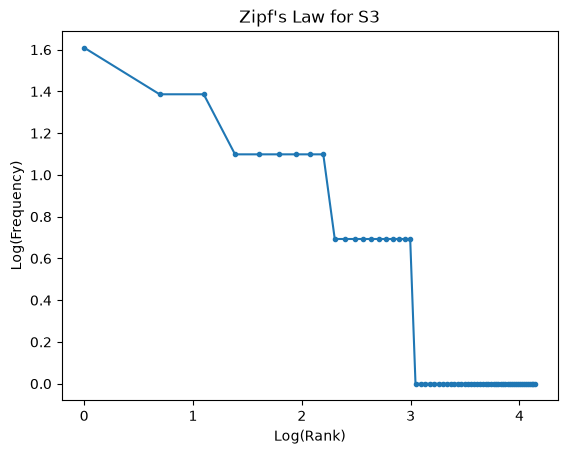


Top 5 bigrams S1: [(('.', 'i'), 7), (('i', 'have'), 4), (('have', 'tried'), 4), (('tried', 'several'), 4), (('several', 'times'), 4)]
Top 5 bigrams S3: [(('tried', 'several'), 4), (('several', 'times'), 4), (('student', 'portal'), 3), (('please', 'help'), 2), (('assignment', 'deadline'), 2)]


In [9]:

from nltk.stem import PorterStemmer
from nltk.util import ngrams
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import string

porter = PorterStemmer()

S1 = []
S2 = []
S3 = []

for index, row in df.iterrows():
    r = process_ticket(row["Ticket_Text"])
    S1 += r["tokens"]
    S2 += [t for t in r["tokens"] if not all(c in string.punctuation for c in t)]
    S3 += r["final"]

S4 = [porter.stem(t) for t in S3]

for name, words in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]:
    print(name, "Tokens:", len(words),
          "Unique:", len(set(words)),
          "TTR:", round(len(set(words)) / len(words), 4))

print("\nTop 10 words S1:", Counter(S1).most_common(10))
print("Top 10 words S3:", Counter(S3).most_common(10))


freq = sorted(Counter(S3).values(), reverse=True)
rank = range(1, len(freq) + 1)


plt.plot(np.log(rank), np.log(freq), marker=".")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.title("Zipf's Law for S3")
plt.show()


print("\nTop 5 bigrams S1:", Counter(ngrams(S1, 2)).most_common(5))
print("Top 5 bigrams S3:", Counter(ngrams(S3, 2)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*